# Regression analysis

Fit Model 9 from the de-identified, prebuilt regression input. Display relative- and absolute-performance estimates and the relative-outcome inbreeding-prediction plot. No regression inputs are rebuilt in this notebook.

Regression Analysis reads `[regression.outputs].directory / author_regression_input.csv`. In this config, that resolves to `data/output/synthetic/regression/author_regression_input.csv`; with `rebuild_input = false`, that exact existing file is used as the input (and a missing file is an error, not a rebuild).

In [1]:
from dataclasses import replace
from io import BytesIO
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

repo_root = Path.cwd()
while not (repo_root / 'pyproject.toml').is_file() and repo_root != repo_root.parent:
    repo_root = repo_root.parent
if not (repo_root / 'pyproject.toml').is_file():
    raise RuntimeError('Start Jupyter from within the academic-inbreeding repository.')
sys.path.insert(0, str(repo_root / 'src'))

from acib.regression.analysis_config import regression_suite_config_from_pipeline_config
from acib.regression.config import load_regression_config
from acib.regression.suite import RegressionSuite



## 1. Load the shared synthetic configuration

Load the shared `pipeline_synthetic.toml`. Regression settings and the prepared regression artifact path come from this configuration. With `rebuild_input = false`, the existing artifact is reused; this notebook does not rebuild it.

In [2]:
config_path = repo_root / 'config' / 'pipeline_synthetic.toml'
config = load_regression_config(config_path)
suite_config = regression_suite_config_from_pipeline_config(config)
print(f'Config: {config_path.relative_to(repo_root)}')
print(f'Rebuild regression input: {config.rebuild_input}')


Config: config/pipeline_synthetic.toml
Rebuild regression input: False


## 2. Configure and fit Model 9

The model terms and outcome families come from the shared configuration. Model 9 is fit for each configured outcome; OLS-HC3 is used for relative outcomes and percentile counts, and negative binomial for total publication counts.

In [3]:
MODEL_ID = 'm9'
model9_spec = next(spec for spec in suite_config.model_specs if spec.model_id == MODEL_ID)
model9_config = replace(suite_config, model_specs=(model9_spec,))
suite = RegressionSuite(data=config.load_inputs().data, config=model9_config)
result = suite.fit()
print(f'Fitted Model 9 for configured outcomes: {result.dependent_variables}')
print('Model 9 formula (example configured outcome):')
print(result.models[(result.dependent_variables[0], MODEL_ID)].formula)


Fitted Model 9 for configured outcomes: ('hazen_perc_med', 'pp_top_10', 'pp_top_5', 'pp_top_1', 'P_top10', 'P_top5', 'P_top1', 'n_public')
Model 9 formula (example configured outcome):
hazen_perc_med ~ C(is_inbred) + academic_age + C(title) + coaffiliation_publication_share + mean_coauthors_per_publication + n_away_years_domestic + n_away_years_abroad + first_year + multi_share + agri_bio_share + arts_hum_share + biochem_share + business_share + chem_eng_share + chem_share + comp_sci_share + decision_share + earth_share + econ_share + energy_share + eng_share + env_sci_share + immuno_share + materials_share + math_share + neuro_share + nursing_share + pharma_share + physics_share + psych_share + soc_sci_share + vet_share + dentistry_share + health_share


## 3. Model 9 estimates: relative and absolute outcomes

Print the regression suite’s standard summaries, including coefficient significance codes. HC3 inference is used for the OLS outcomes; the publication-count outcome uses the configured negative-binomial model and reports its average marginal effects.

In [4]:
if config.print_model_summaries:
    result.print_model_summaries()



Outcome: hazen_perc_med

----------------------------------------------------------------------------------------------------
M9
----------------------------------------------------------------------------------------------------
Dependent variable: hazen_perc_med | Model: m9 (olshc3)
Covariance estimator: HC3 (heteroskedasticity-robust).

Call:
lm(formula = hazen_perc_med ~ C(is_inbred) + academic_age + C(title) + coaffiliation_publication_share + mean_coauthors_per_publication + n_away_years_domestic + n_away_years_abroad + first_year + multi_share + agri_bio_share + arts_hum_share + biochem_share + business_share + chem_eng_share + chem_share + comp_sci_share + decision_share + earth_share + econ_share + energy_share + eng_share + env_sci_share + immuno_share + materials_share + math_share + neuro_share + nursing_share + pharma_share + physics_share + psych_share + soc_sci_share + vet_share + dentistry_share + health_share, data = df)

Residuals:
       Min         1Q     Median   

**Brief interpretation.** Academic inbreeding is associated with lower relative citation impact for three of four outcomes; the PP(top 1%) estimate is negative but not significant. Absolute output is positively associated with inbreeding, including about 9.85 additional predicted publications in the negative-binomial model. These are adjusted associations, not causal effects.

## 4. Relative-outcome predictions by inbreeding status

This reproduces the project’s standard four-panel Model 9 prediction plot. Points are average adjusted predictions with 95% confidence intervals. The axis titles and ticks are explicitly colored for visibility in either light or dark notebook themes.

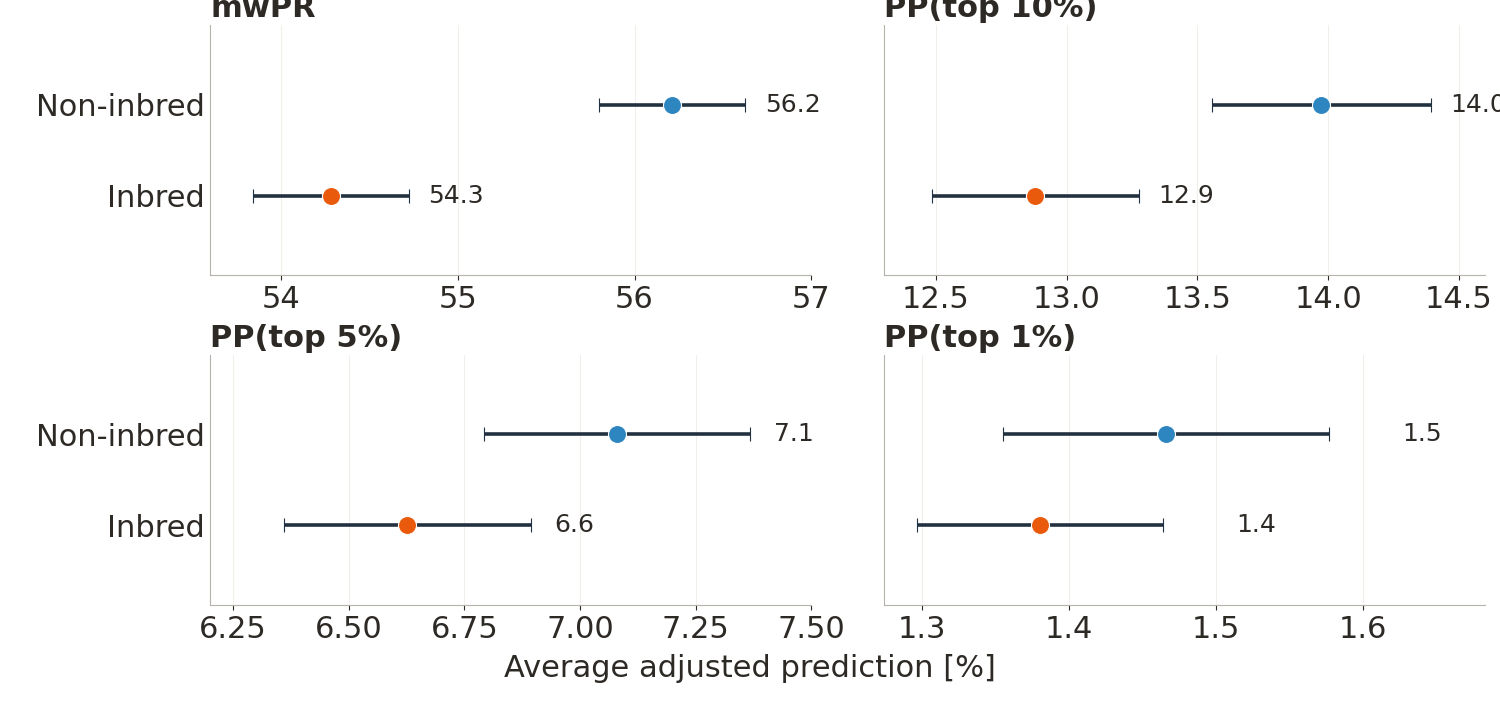

In [5]:
from acib.regression.plots.model9_inbreeding_predictions import Model9InbreedingPredictionPlot

relative_plot = Model9InbreedingPredictionPlot.from_result(result=result)

# The plot module renders labels; this in-memory PNG display writes no file.
relative_buffer = BytesIO()
relative_plot.figure.canvas.draw()
relative_plot.figure.canvas.print_png(relative_buffer)
display(Image(data=relative_buffer.getvalue(), format='png'))
